# LAB 2 for CS4243: Perspective-Aware Virtual Advertisement Overlay
## Notebook 2 — Board localisation, optical flow, temporal variants, and failure monitoring
> **Introduction.** This notebook completes **Stage 1 (Localise)** in `overlaylab/localisation.py` and develops
> **Stage 2 (Track)** in `overlaylab/temporal.py`. Thresholds are chosen on the **validation** annotated frames of
> the common clip (even annotation index), frozen into `outputs/thresholds.json`, and only then reported on the
> **test** frames of the common clip and on each Stage's two stress clips (`python -m overlaylab.report` builds those
> tables from the finished runs). The cell marked **COMPARISON** is the only place where
> `cv2.calcOpticalFlowPyrLK` / `cv2.goodFeaturesToTrack` may appear. Cells marked **REQUIRED** must be completed.

## 1. Imports and reproducible configuration

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
import cv2

from overlaylab import data, metrics, visualize as viz
from overlaylab import supplied as sp
from overlaylab.config import notebook_config, replace
from overlaylab.localisation import localise_board, overlay_frame, evaluate_audit_frames
from overlaylab.temporal import lk_flow, track_board, failure_monitor, TrackInit
from overlaylab.geometry import ransac_homography, dlt_homography, transfer_points
from overlaylab import synthetic as syn
import json

from overlaylab.config import PipelineConfig
stage1 = ROOT / "outputs" / "stage1_settings.json"
config = PipelineConfig.from_json(stage1.read_text()) if stage1.exists() else notebook_config()
config.resize_width = data.NOTEBOOK_WIDTH
indices, frames, factor = data.load_notebook_subset()
reference_full = data.load_reference()
reference = sp.resize_width(reference_full, int(round(reference_full.shape[1] * factor)))
config.localisation.warp.reference_shape = reference.shape[:2]
artwork = data.load_artwork("ad")
gt_val = data.subset_gt_corners(indices, factor, "validation"); gt_test = data.subset_gt_corners(indices, factor, "test")
by_index = {i: frames[indices.index(i)] for i in indices}
print(len(frames), "subset frames;", len(gt_val), "validation and", len(gt_test), "test annotated frames")

63 subset frames; 13 validation and 13 test annotated frames


## 2. Stage 1 Localise — localise the board on the validation frames (REQUIRED)
Run `evaluate_audit_frames` on the validation frames, look at the corner-error distribution, **choose the success
threshold**, and freeze it. Choose detector, descriptor, matcher, RANSAC, flow, reinitialisation and monitor settings on validation/synthetic data before running test/stress cells. Record those choices in `config` here. For final native-resolution settings, use only full-resolution validation frames; the later preview cells are fixed-setting diagnostics.

frame    0: error   0.48%  matches  189  inliers  179  ratio 0.95  residual 0.64px  status True
frame   32: error   0.47%  matches  158  inliers  152  ratio 0.96  residual 0.89px  status True
frame   80: error   0.39%  matches  134  inliers  129  ratio 0.96  residual 0.85px  status True
frame  112: error   0.58%  matches  171  inliers  161  ratio 0.94  residual 0.70px  status True
frame  144: error   0.83%  matches  117  inliers  108  ratio 0.92  residual 0.74px  status True
frame  176: error   0.48%  matches  200  inliers  192  ratio 0.96  residual 0.77px  status True
frame  208: error   0.74%  matches  144  inliers  128  ratio 0.89  residual 0.80px  status True
frame  240: error   0.51%  matches   83  inliers   73  ratio 0.88  residual 0.86px  status True
frame  272: error   0.48%  matches  142  inliers  134  ratio 0.94  residual 0.76px  status True
frame  320: error   0.47%  matches  145  inliers  138  ratio 0.95  residual 0.79px  status True
frame  384: error   0.41%  matches  178 

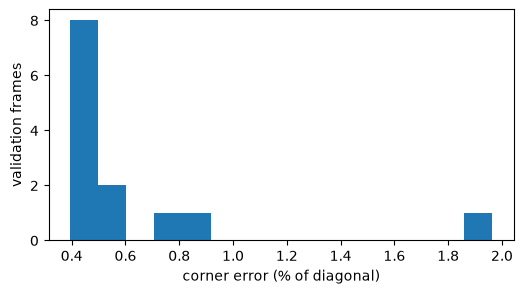

frozen success threshold: 0.01


In [2]:
val = evaluate_audit_frames(reference, {i: by_index[i] for i in gt_val}, gt_val, config.localisation)
for f, r in val["per_frame"].items():
    print(f"frame {f:4d}: error {r['error']*100:6.2f}%  matches {r['n_matches']:4d}  inliers {r['n_inliers']:4d}  ratio {r['inlier_ratio']:.2f}  residual {r['median_residual']:.2f}px  status {r['status']}")
errs = np.array([r["error"] for r in val["per_frame"].values()])
plt.figure(figsize=(6, 3)); plt.hist(errs[np.isfinite(errs)] * 100, bins=15); plt.xlabel("corner error (% of diagonal)"); plt.ylabel("validation frames"); plt.show()

# YOUR CODE HERE — choose config.localisation.success_threshold from the validation distribution above,
# justify it in the report, then freeze it. Example: the 90th percentile rounded up, or a fixed 2%.
config.localisation.success_threshold = 0.01 # 90th quantile (0.0079) rounded up to 0.01
Path(ROOT / "outputs").mkdir(exist_ok=True)
(ROOT / "outputs" / "thresholds.json").write_text(json.dumps(config.thresholds(), indent=2))   # full algorithm configuration; processing width/reference shape are set per run
print("frozen success threshold:", config.localisation.success_threshold)

## 3. Stage 1 Localise — report on the test frames (REQUIRED)
With the threshold frozen, report median / 90th-percentile error, the success fraction, inliers per frame, and the two worst
cases (state explicitly if they pass the frozen threshold) with the match visualisation, residual histogram and projected quadrilateral. This is the common-clip (test)
row of the Stage 1 stress table at the notebook resolution; the full-resolution table, including the viewpoint and
scale rows, is generated by `python -m overlaylab.report` with the frozen configuration (section 10).

test summary: {'n': 13, 'median': 0.0047, 'p90': 0.0067, 'success': 1.0, 'failed': 0}


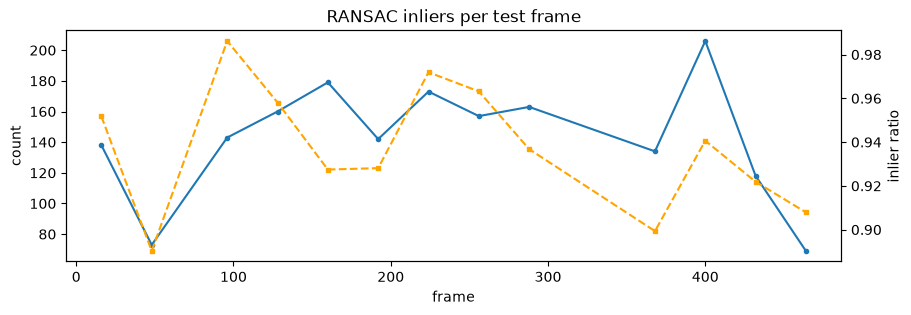

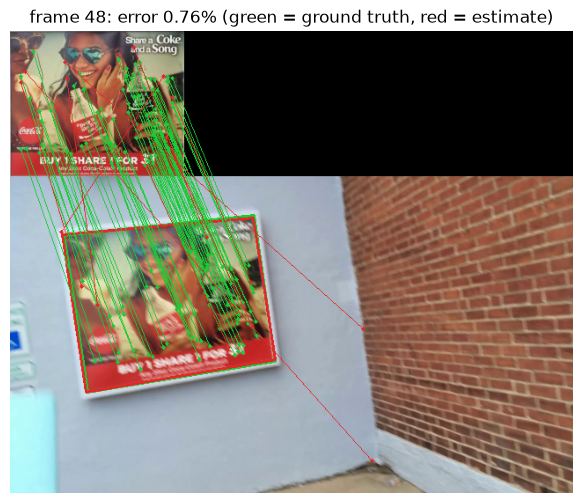

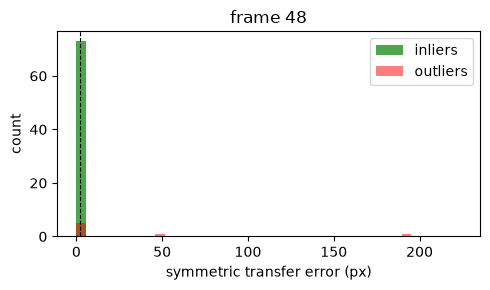

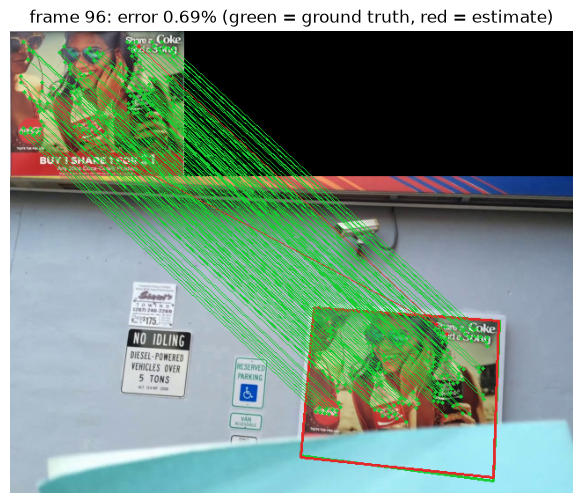

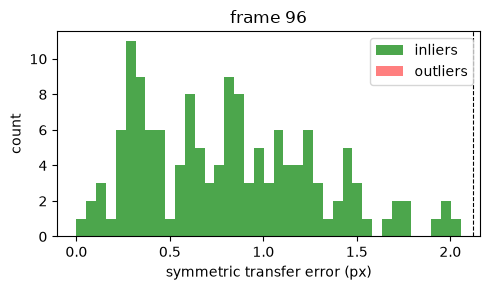

In [3]:
test = evaluate_audit_frames(reference, {i: by_index[i] for i in gt_test}, gt_test, config.localisation)
print("test summary:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in test["summary"].items()})
fr = sorted(test["per_frame"]); inl = [test["per_frame"][f]["n_inliers"] for f in fr]; rat = [test["per_frame"][f]["inlier_ratio"] for f in fr]
fig, ax = plt.subplots(figsize=(10, 3)); ax.plot(fr, inl, "o-", ms=3, label="inliers"); ax.set_xlabel("frame"); ax.set_ylabel("count")
ax2 = ax.twinx(); ax2.plot(fr, rat, "s--", ms=3, color="orange", label="ratio"); ax2.set_ylabel("inlier ratio"); ax.set_title("RANSAC inliers per test frame"); plt.show()

# YOUR CODE HERE — pick two worst test frames and show the match visualisation, the residual histogram and the quadrilateral
worst = sorted(fr, key=lambda f: -test["per_frame"][f]["error"])[:2]
for f in worst:
    H, corners, pairs, inliers, diag = localise_board(reference, by_index[f], config.localisation)
    plt.figure(figsize=(12, 6)); plt.imshow(viz.draw_matches(reference, viz.draw_quad(viz.draw_quad(by_index[f], gt_test[f], viz.GREEN), corners, viz.RED), diag["keypoints_ref"], diag["keypoints_frame"], pairs, inliers)); plt.axis("off")
    plt.title(f"frame {f}: error {test['per_frame'][f]['error']*100:.2f}% (green = ground truth, red = estimate)"); plt.show()
    if len(diag["residuals"]): viz.plot_residual_histogram(diag["residuals"], inliers, config.localisation.ransac.threshold, f"frame {f}"); plt.show()

## 4. RANSAC versus a least-squares fit to all ratio-test matches
Same matches, same settings, only the estimator changes.

In [4]:
rows = []
for f in sorted(gt_test):
    H, corners, pairs, inliers, diag = localise_board(reference, by_index[f], config.localisation)
    src = diag["keypoints_ref"][pairs[:, 0]]; dst = diag["keypoints_frame"][pairs[:, 1]]
    H_ls, _, ok = dlt_homography(src, dst) if len(pairs) >= 4 else (None, None, False)
    e_ls = metrics.corner_error(transfer_points(H_ls, sp.rect_corners(reference.shape[1], reference.shape[0])), gt_test[f]) if ok else float("inf")
    rows.append((f, test["per_frame"][f]["error"], e_ls))
print(f"{'frame':>5s} {'RANSAC':>8s} {'least-squares':>14s}")
for f, a, b in rows: print(f"{f:5d} {a*100:7.2f}% {b*100:13.2f}%")

frame   RANSAC  least-squares
   16    0.43%         17.99%
   48    0.76%         85.09%
   96    0.69%          4.13%
  128    0.34%          4.26%
  160    0.41%          1.63%
  192    0.62%          9.27%
  224    0.25%          2.87%
  256    0.47%          8.22%
  288    0.36%          9.75%
  368    0.49%          1.88%
  400    0.47%          2.39%
  432    0.45%          1.60%
  464    0.48%         54.49%


## 5. The viewpoint clip — affine versus homography (REQUIRED)
Every clip other than the common clip isolates one capture factor and is named by it (`data.clip_factor`); each Stage
reports on its two stress clips, `data.stress_clips(stage)`. On the **viewpoint** clip the camera rotates *and* moves
around the poster, so the board's image is a general quadrilateral and a 6-parameter affine model cannot place the
artwork. Fit an affine transformation by least squares to the *same* inlier correspondences that RANSAC selected and
compare the corner error of both models on every annotated frame (the same comparison fills the *affine* column of the
Stage 1 stress table). Thresholds stay frozen: nothing is tuned here.

stress clips per Stage: {1: {'viewpoint': 'coke_perspective', 'scale': 'coke_scale'}, 2: {'blur': 'coke_blur', 'exit': 'coke_out_of_view'}, 3: {'viewpoint': 'coke_perspective', 'combined': 'coke_unconstrained'}}
viewpoint  coke_perspective   scale [0.584, 1.067]  rotation [-21.0, 36.5] deg  keystone 1.586  affine residual of the GT quads 9.8%
scale      coke_scale         scale [0.285, 1.001]  rotation [-7.2, 0.7] deg  keystone 1.058  affine residual of the GT quads 1.6%
blur       coke_blur          scale [0.81, 1.173]  rotation [-18.3, 8.5] deg  keystone 1.16  affine residual of the GT quads 2.4%
exit       coke_out_of_view   scale [0.945, 1.217]  rotation [-9.1, 0.8] deg  keystone 1.178  affine residual of the GT quads 2.4%
combined   coke_unconstrained scale [0.755, 1.331]  rotation [-78.6, 80.3] deg  keystone 1.563  affine residual of the GT quads 9.3%

coke_perspective: frame  homography   affine
    0       0.50%    0.87%
   16       0.34%    0.85%
   32       0.37%    1.23%
   

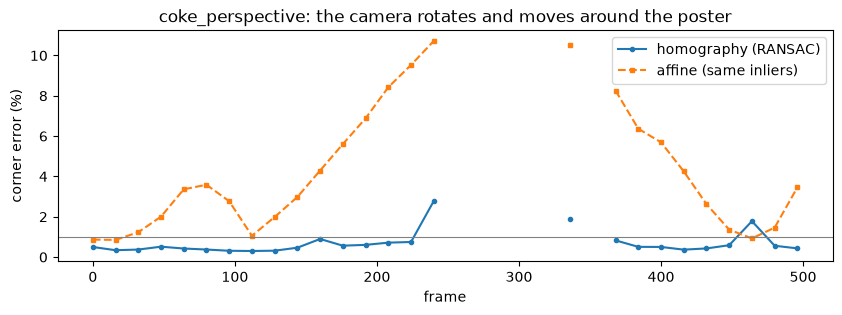

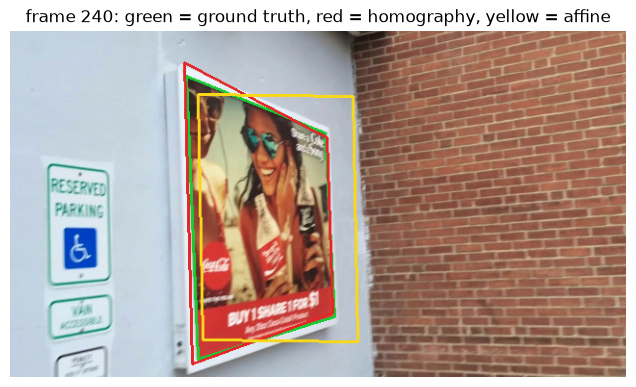

keystone range: 1.030–1.566; Pearson correlation with affine error: 0.998
strongest keystone among successful localisations: frame 240, ratio 1.535, affine error 10.72%


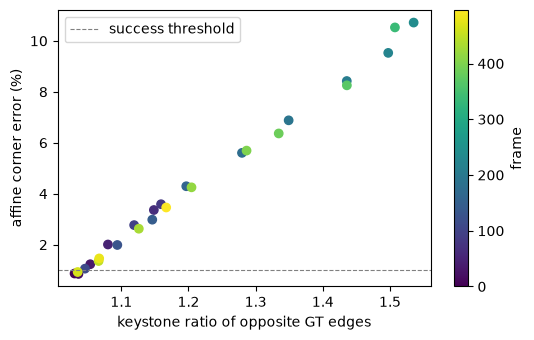

An affine map keeps opposite sides parallel, so it cannot represent the edge convergence caused by the camera orbit. A homography has the two additional projective degrees of freedom needed for that keystone distortion.


In [5]:
print("stress clips per Stage:", data.stress_clips())
for cid in data.stress_clip_ids():
    g = sp.read_json(data.DATASET_SUMMARY)["diagnostic_clips"][cid]["geometry"]
    print(f"{data.clip_factor(cid):10s} {cid:18s} scale {g['scale_range']}  rotation {g['in_plane_rotation_deg']} deg  keystone {g['max_keystone']}  affine residual of the GT quads {g['max_affine_residual']*100:.1f}%")
from overlaylab.report import affine_from_points      # least-squares 6-parameter affine map as a 3 x 3 matrix

lvl2 = data.stress_clips(1)["viewpoint"]
video_l2, _ = data.clip_paths(lvl2)                                            # same poster, same reference image
gt_l2 = data.load_diagnostic_corners(lvl2, scale=factor)
frames_l2 = {i: fr for i, fr in sp.iter_video(video_l2, step=data.GT_STRIDE, width=frames[0].shape[1]) if i in gt_l2}
ref_rect = sp.rect_corners(reference.shape[1], reference.shape[0])
rows_l2 = {}
for f in sorted(frames_l2):
    H, corners, pairs, inliers, diag = localise_board(reference, frames_l2[f], config.localisation)
    if not diag["status"] or inliers.sum() < 4:
        rows_l2[f] = (float("inf"), float("inf"), None, None); continue
    src = diag["keypoints_ref"][pairs[inliers, 0]]; dst = diag["keypoints_frame"][pairs[inliers, 1]]
    H_aff = affine_from_points(src, dst)
    rows_l2[f] = (metrics.corner_error(corners, gt_l2[f]), metrics.corner_error(transfer_points(H_aff, ref_rect), gt_l2[f]), corners, transfer_points(H_aff, ref_rect))
print(f"\n{lvl2}: {'frame':>5s} {'homography':>11s} {'affine':>8s}")
for f, (eh, ea, *_) in rows_l2.items(): print(f"{f:5d} {eh*100:10.2f}% {ea*100:7.2f}%")
eh = np.array([r[0] for r in rows_l2.values()]); ea = np.array([r[1] for r in rows_l2.values()]); ok = np.isfinite(eh) & np.isfinite(ea)
print(f"median corner error: homography {np.median(eh[ok])*100:.2f}%  affine {np.median(ea[ok])*100:.2f}%   success@{config.localisation.success_threshold:.0%}: {np.mean(eh < config.localisation.success_threshold):.0%} vs {np.mean(ea < config.localisation.success_threshold):.0%}")
fr_l2 = sorted(rows_l2); plt.figure(figsize=(10, 3)); plt.plot(fr_l2, eh * 100, "o-", ms=3, label="homography (RANSAC)"); plt.plot(fr_l2, ea * 100, "s--", ms=3, label="affine (same inliers)")
plt.axhline(config.localisation.success_threshold * 100, color="gray", lw=.8); plt.xlabel("frame"); plt.ylabel("corner error (%)"); plt.title(f"{lvl2}: the camera rotates and moves around the poster"); plt.legend(); plt.show()
f = max((f for f in rows_l2 if rows_l2[f][2] is not None), key=lambda f: rows_l2[f][1])
img = viz.draw_quad(viz.draw_quad(viz.draw_quad(frames_l2[f], gt_l2[f], viz.GREEN), rows_l2[f][2], viz.RED), rows_l2[f][3], viz.YELLOW)
plt.figure(figsize=(8, 4.5)); plt.imshow(img); plt.axis("off"); plt.title(f"frame {f}: green = ground truth, red = homography, yellow = affine"); plt.show()
# YOUR CODE HERE — relate the affine error to the keystone of the annotated quadrilateral (ratio of opposite edge lengths)
# and explain, from the camera motion, why the affine model breaks down while the homography holds (Question 2).

def opposite_edge_keystone(corners):
    # TL-TR, TR-BR, BR-BL, BL-TL; an affine map preserves equality of each opposite-edge pair.
    c = np.asarray(corners, dtype=float)
    edge_lengths = np.linalg.norm(np.roll(c, -1, axis=0) - c, axis=1)
    horizontal = max(edge_lengths[0] / max(edge_lengths[2], 1e-9), edge_lengths[2] / max(edge_lengths[0], 1e-9))
    vertical = max(edge_lengths[1] / max(edge_lengths[3], 1e-9), edge_lengths[3] / max(edge_lengths[1], 1e-9))
    return max(horizontal, vertical)

keystone_frames = sorted(rows_l2)
keystone = np.array([opposite_edge_keystone(gt_l2[f]) for f in keystone_frames])
affine_error = np.array([rows_l2[f][1] for f in keystone_frames])
finite = np.isfinite(affine_error)
correlation = np.corrcoef(keystone[finite], affine_error[finite])[0, 1] if finite.sum() > 1 else float("nan")
finite_indices = np.flatnonzero(finite)
worst_keystone_frame = keystone_frames[int(finite_indices[np.argmax(keystone[finite])])]
print(f"keystone range: {keystone.min():.3f}–{keystone.max():.3f}; Pearson correlation with affine error: {correlation:.3f}")
print(f"strongest keystone among successful localisations: frame {worst_keystone_frame}, "
      f"ratio {opposite_edge_keystone(gt_l2[worst_keystone_frame]):.3f}, affine error {rows_l2[worst_keystone_frame][1]*100:.2f}%")
plt.figure(figsize=(5.5, 3.5))
plt.scatter(keystone[finite], affine_error[finite] * 100, c=np.array(keystone_frames)[finite], cmap="viridis")
plt.axhline(config.localisation.success_threshold * 100, color="gray", ls="--", lw=.8, label="success threshold")
plt.xlabel("keystone ratio of opposite GT edges"); plt.ylabel("affine corner error (%)")
plt.colorbar(label="frame"); plt.legend(); plt.tight_layout(); plt.show()
print("An affine map keeps opposite sides parallel, so it cannot represent the edge convergence caused by the camera orbit. "
      "A homography has the two additional projective degrees of freedom needed for that keystone distortion.")

## 6. COMPARISON — `cv2.warpPerspective`: single-frame overlay and the parallax question (**Question 2**)
Warp a *whole frame* with the board-fitted homography between two frames that include camera translation: the board aligns,
the background does not. Do it on the viewpoint clip, where the camera orbits the poster, and explain why the parallax outside
the board does not harm the overlay.

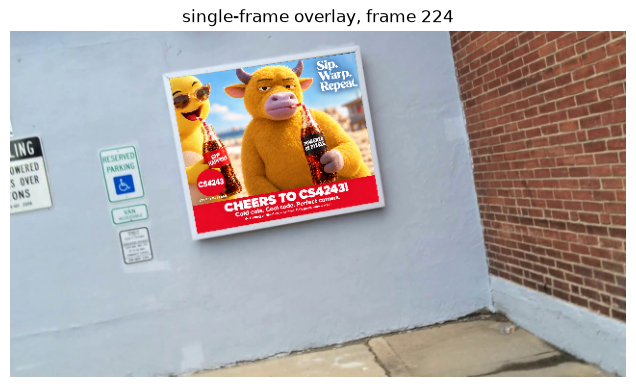

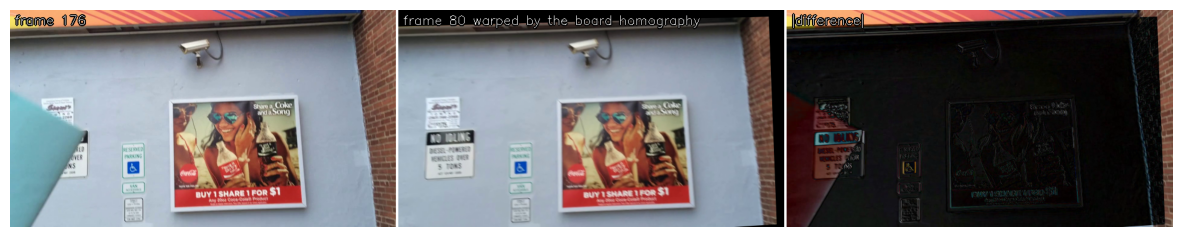

viewpoint frames 224 -> 496: median |difference| inside board 0.059, valid background 0.072


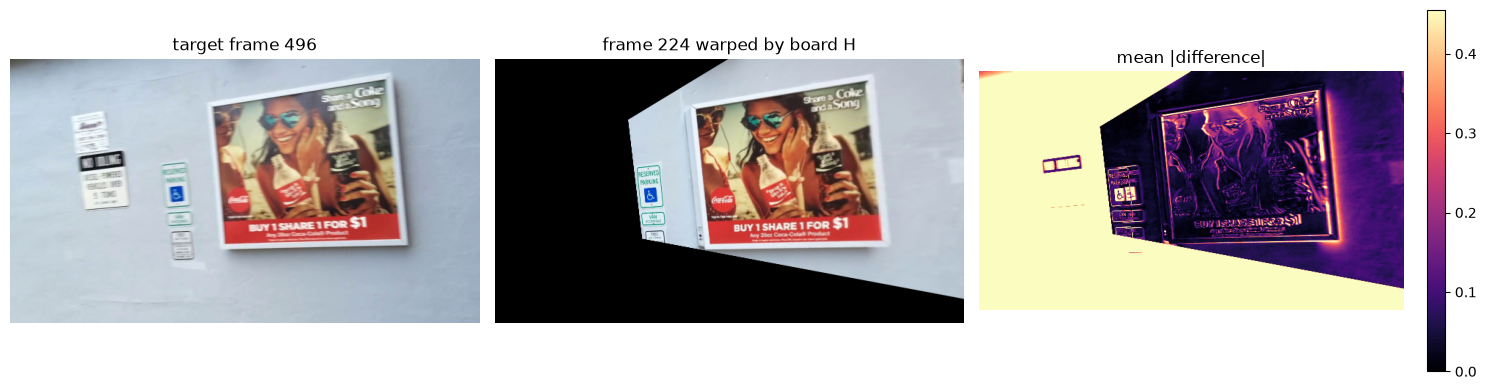

The board is one plane, so its homography aligns it. Background points have different depths and therefore different image motion (parallax); this does not harm the overlay because artwork is painted only inside the board coverage.


In [6]:
f = sorted(gt_test)[len(gt_test) // 2]
H, corners, *_ = localise_board(reference, by_index[f], config.localisation)
plt.figure(figsize=(8, 4.5)); plt.imshow(overlay_frame(by_index[f], artwork, H, config.localisation)); plt.axis("off"); plt.title(f"single-frame overlay, frame {f}"); plt.show()
fa, fb = sorted(gt_val)[2], sorted(gt_val)[5]
Ha, *_ = localise_board(reference, by_index[fa], config.localisation); Hb, *_ = localise_board(reference, by_index[fb], config.localisation)
H_ab = Hb @ np.linalg.inv(Ha)                      # frame a -> frame b through the board plane
warped_a = cv2.warpPerspective(by_index[fa], H_ab.astype(np.float32), (frames[0].shape[1], frames[0].shape[0]))
plt.figure(figsize=(15, 4)); plt.imshow(viz.montage([viz.label(by_index[fb], f"frame {fb}"), viz.label(warped_a, f"frame {fa} warped by the board homography"), viz.label(np.abs(warped_a - by_index[fb]), "|difference|")], cols=3)); plt.axis("off"); plt.show()
# YOUR CODE HERE — repeat on two viewpoint-clip frames from frames_l2 (the orbit gives the strongest parallax) and show the |difference| panel

valid_l2 = [f for f in sorted(frames_l2) if rows_l2[f][2] is not None]
# Choose the valid pair with the largest mean GT-corner displacement as a reproducible large-viewpoint-change pair.
fa_l2, fb_l2 = max(((a, b) for i, a in enumerate(valid_l2) for b in valid_l2[i + 1:]),
                       key=lambda ab: np.mean(np.linalg.norm(gt_l2[ab[0]] - gt_l2[ab[1]], axis=1)))
Ha_l2, *_ = localise_board(reference, frames_l2[fa_l2], config.localisation)
Hb_l2, *_ = localise_board(reference, frames_l2[fb_l2], config.localisation)
H_ab_l2 = Hb_l2 @ np.linalg.inv(Ha_l2)
height_l2, width_l2 = frames_l2[fb_l2].shape[:2]
warped_l2 = cv2.warpPerspective(frames_l2[fa_l2], H_ab_l2.astype(np.float32), (width_l2, height_l2))
coverage_l2 = cv2.warpPerspective(np.ones((height_l2, width_l2), np.uint8), H_ab_l2.astype(np.float32),
                                  (width_l2, height_l2), flags=cv2.INTER_NEAREST) > 0
difference_l2 = np.mean(np.abs(warped_l2.astype(float) - frames_l2[fb_l2].astype(float)), axis=2)
board_l2 = sp.quad_mask((height_l2, width_l2), gt_l2[fb_l2]) & coverage_l2
background_l2 = (~sp.quad_mask((height_l2, width_l2), gt_l2[fb_l2])) & coverage_l2
print(f"viewpoint frames {fa_l2} -> {fb_l2}: median |difference| inside board "
      f"{np.median(difference_l2[board_l2]):.3f}, valid background {np.median(difference_l2[background_l2]):.3f}")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(frames_l2[fb_l2]); axes[0].set_title(f"target frame {fb_l2}")
axes[1].imshow(warped_l2); axes[1].set_title(f"frame {fa_l2} warped by board H")
im = axes[2].imshow(difference_l2, cmap="magma", vmin=0, vmax=np.percentile(difference_l2[coverage_l2], 99))
axes[2].set_title("mean |difference|"); fig.colorbar(im, ax=axes[2], fraction=.046)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print("The board is one plane, so its homography aligns it. Background points have different depths and therefore "
      "different image motion (parallax); this does not harm the overlay because artwork is painted only inside the board coverage.")

## 7. Stage 2 Track — Lucas–Kanade flow between consecutive frames
Consecutive full-rate frames (at 640 px) around the occlusion are loaded here so that the per-frame motion is small.
Inspect the eigenvalues of the structure tensor at the tracked points: points on the straight board edges have a small
$\lambda_2$ (aperture problem), points under the occluder violate brightness constancy (**Question 3**).

82 tracked points, 5 valid; median |flow| 26.94 px


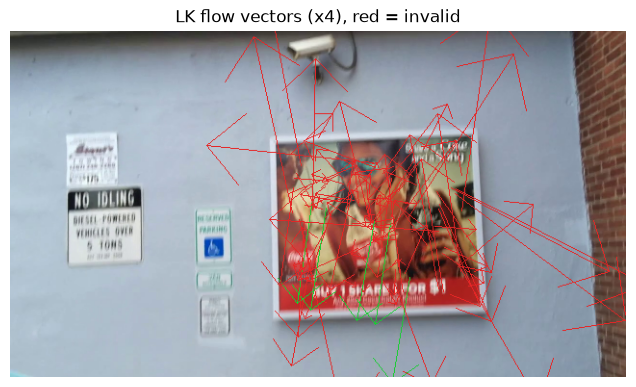

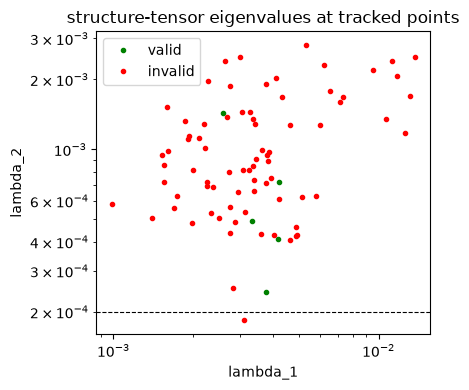

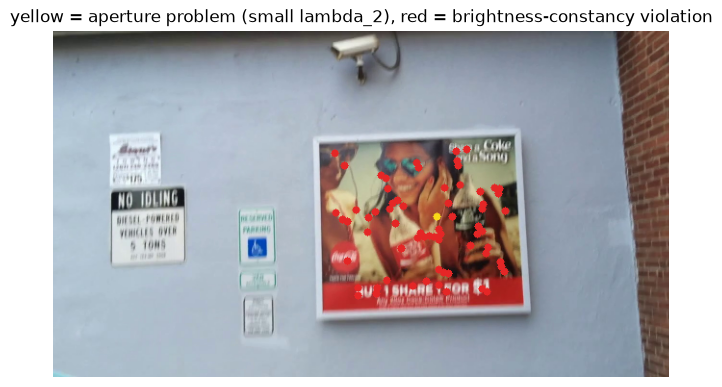

In [7]:
seg_idx, seg, _ = data.load_consecutive_frames(170, 240)
g0, g1 = sp.to_gray(seg[0]), sp.to_gray(seg[1])
H0, c0, pairs0, inl0, diag0 = localise_board(reference, seg[0], config.localisation)
pts = diag0["keypoints_frame"][pairs0[inl0, 1]]
d, eig, resid, valid = lk_flow(g0, g1, pts, config.track.flow)
print(f"{len(pts)} tracked points, {valid.sum()} valid; median |flow| {np.median(np.linalg.norm(d[valid], axis=1)):.2f} px")
plt.figure(figsize=(8, 4.5)); plt.imshow(viz.draw_flow(seg[0], pts, d, valid, scale=4)); plt.axis("off"); plt.title("LK flow vectors (x4), red = invalid"); plt.show()
viz.plot_eigenvalues(eig, valid, config.track.flow.min_eigenvalue, "structure-tensor eigenvalues at tracked points"); plt.show()
# where do the invalid points lie? edge-dominated (small lambda_2) versus brightness-constancy violations (large residual)
aperture = eig[:, 1] < config.track.flow.min_eigenvalue; residual_fail = resid > config.track.flow.max_residual
plt.figure(figsize=(8, 4.5)); plt.imshow(viz.draw_points(viz.draw_points(seg[0], pts[aperture], viz.YELLOW, 4), pts[residual_fail & ~aperture], viz.RED, 4)); plt.axis("off")
plt.title("yellow = aperture problem (small lambda_2), red = brightness-constancy violation"); plt.show()

### COMPARISON CELL — `cv2.calcOpticalFlowPyrLK` (the only cell where it is permitted)

In [8]:
p0 = pts.astype(np.float32).reshape(-1, 1, 2)
p1, st, err = cv2.calcOpticalFlowPyrLK(sp.to_uint8(g0), sp.to_uint8(g1), p0, None, winSize=(15, 15), maxLevel=2)
d_cv = (p1 - p0).reshape(-1, 2); both = valid & (st.ravel() == 1)
print(f"median |ours - cv2| over {both.sum()} points both consider valid: {np.median(np.linalg.norm(d[both] - d_cv[both], axis=1)):.3f} px")

median |ours - cv2| over 5 points both consider valid: 0.023 px


## 8. Stage 2 Track — the two temporal variants (REQUIRED)
Run both variants on the consecutive segment and compare jitter and drift against the interpolated ground truth. Then
plot the per-frame statistics your monitor consumes. Flicker (independent) versus drift (flow-assisted) is the first part
of **Question 3**.

independent    ok 66/70  reinits 66  jitter 2.06px  errors on annotated frames [0.48, 0.62, 0.74, 0.25]
flow_assisted  ok 69/70  reinits 8  jitter 2.24px  errors on annotated frames [0.43, 0.6, 0.98, 0.65]


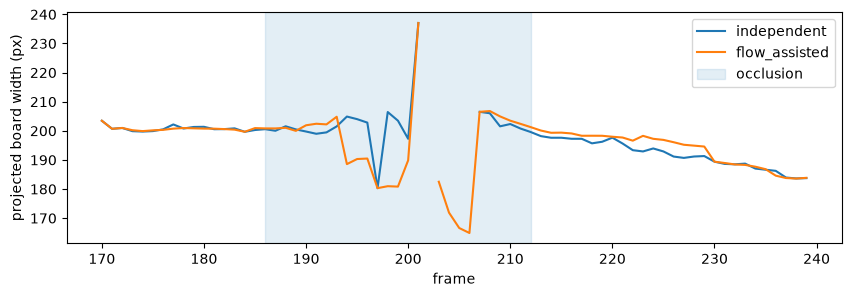

independent   : max 0 frames since reinit; median error at >=16 frames: n/a
flow_assisted : max 20 frames since reinit; median error at >=16 frames: 0.63%


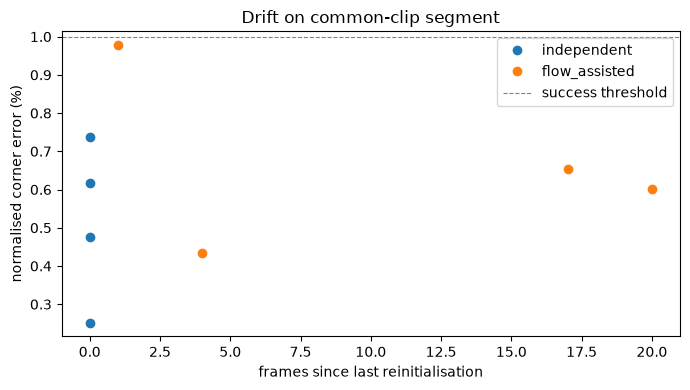

In [9]:
gt_all = data.load_gt_corners(scale=factor); gt_frames = sorted(gt_all); gt_list = [gt_all[f] for f in gt_frames]
results = {}
for variant in ("independent", "flow_assisted"):
    cfg = replace(config.track, variant=variant)
    results[variant] = track_board(seg, TrackInit(reference, config.localisation), cfg)
    res = results[variant]
    pred = {seg_idx[k]: res.corners[k] for k in range(len(seg_idx)) if res.status[k] == "ok"}
    errs = {f: metrics.corner_error(pred[f], gt_all[f]) for f in pred if f in gt_all}
    print(f"{variant:14s} ok {sum(s == 'ok' for s in res.status)}/{len(seg)}  reinits {len(res.reinit_frames)}  "
          f"jitter {metrics.jitter(pred, gt_frames, gt_list):.2f}px  errors on annotated frames {[round(e*100,2) for e in errs.values()]}")
fig, ax = plt.subplots(figsize=(10, 3))
for variant, res in results.items():
    ax.plot(seg_idx, [np.linalg.norm(c[1] - c[0]) if np.all(np.isfinite(c)) else np.nan for c in res.corners], label=variant)
occlusion_events = sp.read_json(data.DATASET_SUMMARY)["common_clip"]["events"]["occlusion"]   # [start, end] frame pairs
for k, (a, b) in enumerate(e for e in occlusion_events if e[1] >= seg_idx[0] and e[0] <= seg_idx[-1]):
    ax.axvspan(a, b, alpha=.12, color="tab:blue", label="occlusion" if k == 0 else None)
ax.set_xlabel("frame"); ax.set_ylabel("projected board width (px)"); ax.legend(); plt.show()

# YOUR CODE HERE — drift: corner error as a function of frames since the last reinitialisation (use metrics.drift)

drift_by_variant = {}
fig, ax = plt.subplots(figsize=(7, 4))
for variant, res in results.items():
    audit_errors = {}
    for local_index, source_frame in enumerate(seg_idx):
        if source_frame in gt_all and res.status[local_index] == "ok":
            audit_errors[source_frame] = metrics.corner_error(res.corners[local_index], gt_all[source_frame])
    # reinit_frames uses segment-local indices; metrics.drift needs the same global frame coordinates as audit_errors.
    reinit_source_frames = [seg_idx[i] for i in res.reinit_frames if i < len(seg_idx)]
    drift_pairs = metrics.drift(audit_errors, reinit_source_frames)
    drift_by_variant[variant] = drift_pairs
    if drift_pairs:
        age, error = np.asarray(drift_pairs).T
        ax.plot(age, error * 100, "o", label=variant)
        late = error[age >= 16]
        late_text = f"{np.median(late)*100:.2f}%" if len(late) else "n/a"
        print(f"{variant:14s}: max {int(age.max())} frames since reinit; median error at >=16 frames: {late_text}")
ax.axhline(config.localisation.success_threshold * 100, color="gray", ls="--", lw=.8, label="success threshold")
ax.set_xlabel("frames since last reinitialisation"); ax.set_ylabel("normalised corner error (%)")
ax.set_title("Drift on common-clip segment"); ax.legend(); plt.tight_layout(); plt.show()

## 9. Failure monitor diagnostics (settings already frozen in section 2)
Do not retune from the test/stress plots. Use the synthetic stress sequences for events the common clip does not contain (whip-pan, illumination step, near-total
occlusion). Plot the statistics around each event, identify which fires first, and name the violated assumption.
**Question 3** asks the same on the **combined** clip (`data.stress_clips(3)["combined"]`, run by `run_pipeline --all`
for the Stage 3 table; then `viz.plot_monitor_timeline` on its `_stats.json`): which statistic fired first at the card
crossing (frames 210-222, 302-314) and at the fast rotation, and how the monitor separates occlusion from drift. The
**blur** and **exit** clips of the Stage 2 table show the other two failure modes (brightness constancy, board leaving the frame).

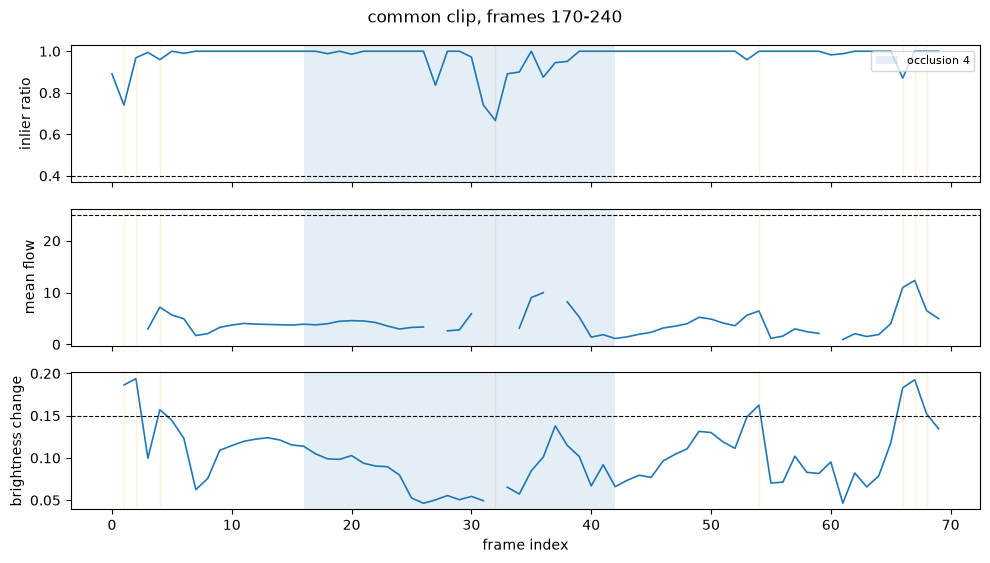

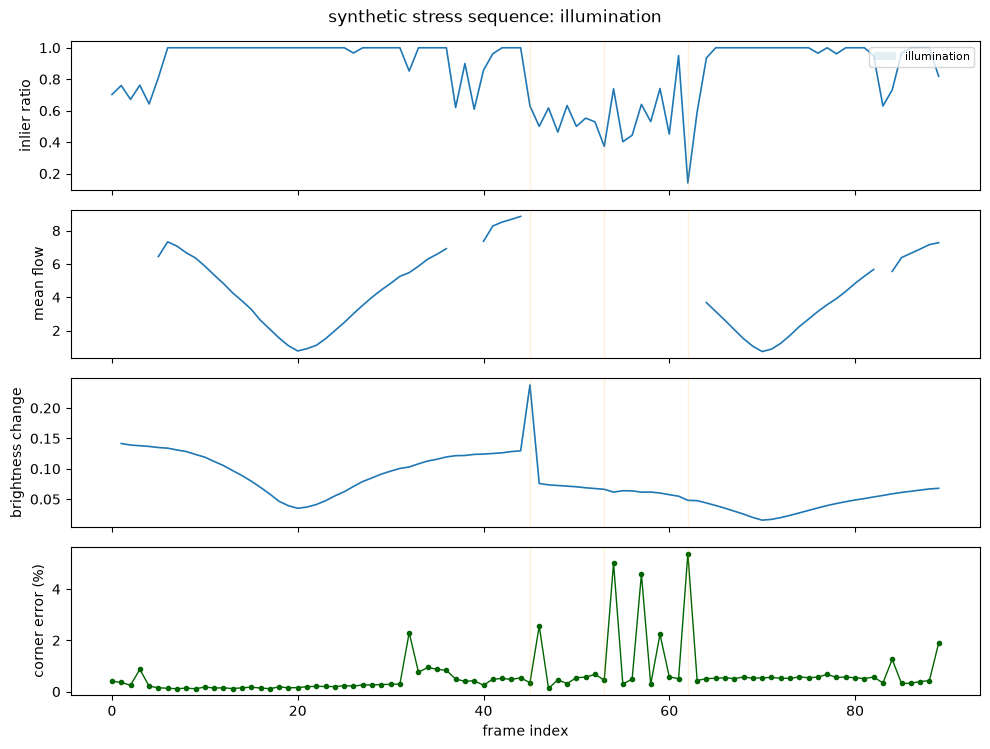

first non-OK flag: (45, ('REINIT', 'brightness_change'))
Frozen settings unchanged; these are diagnostic plots.


In [10]:
from overlaylab.synthetic import stress_specs, render_sequence
flags = failure_monitor(results["flow_assisted"].stats, config.track.monitor)
events_in_seg = {f"occlusion {k}": (a - seg_idx[0], b - seg_idx[0]) for k, (a, b) in enumerate(occlusion_events)
                 if b >= seg_idx[0] and a <= seg_idx[-1]}
viz.plot_monitor_timeline(results["flow_assisted"].stats, flags, events_in_seg,
                          thresholds={"inlier_ratio": config.track.monitor.min_inlier_ratio, "mean_flow": config.track.monitor.max_mean_flow,
                                      "brightness_change": config.track.monitor.max_brightness_change}, title="common clip, frames 170-240"); plt.show()
name = "illumination"   # try: "whip_pan", "near_total_occlusion", "exit", "long_track"
spec = stress_specs()[name]; seq = render_sequence(spec)
ref_syn = sp.resize_width(seq.board, 480); cfg_syn = replace(config.localisation, warp=replace(config.localisation.warp, reference_shape=ref_syn.shape[:2]))
res_syn = track_board(seq.frames, TrackInit(ref_syn, cfg_syn), replace(config.track, variant="flow_assisted"))
flags_syn = failure_monitor(res_syn.stats, config.track.monitor)
errs_syn = {i: metrics.corner_error(res_syn.corners[i], seq.corners[i]) for i in range(len(seq.frames))}
viz.plot_monitor_timeline(res_syn.stats, flags_syn, seq.events, errors=errs_syn, title=f"synthetic stress sequence: {name}"); plt.show()
print("first non-OK flag:", next(((i, f) for i, f in enumerate(flags_syn) if f[0] != "OK"), None))
assert json.loads((ROOT / "outputs" / "thresholds.json").read_text()) == config.thresholds(), "settings changed after freezing: choose settings on validation first, then rerun"
print("Frozen settings unchanged; these are diagnostic plots.")

## 10. The stress tables of Stages 1 and 2
After Notebook 3 has frozen the occlusion settings in `outputs/thresholds.json`, the full-resolution runs and the three stress tables are two commands, run from
`code/` in a terminal (about 30 minutes of compute for the eight videos; `--all` skips videos that already exist):

    python -m overlaylab.run_pipeline --all --thresholds outputs/thresholds.json
    python -m overlaylab.report

`report` runs `localise_board` on the annotated frames of the common clip (validation / test) and of the viewpoint and
scale clips for the Stage 1 table (including the affine column of section 5), reads the `_stats.json` of each run for the
Stage 2 table (common clip with both temporal variants, blur and exit clips with the flow-assisted one), and scores the
saved masks and the evaluator reports for the Stage 3 table. Paste `outputs/stress_tables.md` into the report and explain
the row each question points at. The cell below loads the tables once they exist.

# Stress tables

Generated by `python -m overlaylab.report` with the frozen thresholds (success threshold 1.00%), artwork `ad`, full resolution.

## Stage 1 Localise

| row | frames | median err | p90 err | success | inliers (median) | inlier ratio | affine median err | affine success |
|---|---|---|---|---|---|---|---|---|
| common · validation | 13 | 0.43% | 0.56% | 85% | 96 | 0.842 | 0.71% | 54% |
| common · test | 13 | 0.36% | 0.52% | 92% | 98 | 0.886 | 0.87% | 62% |
| viewpoint (coke_perspective) | 32 | 0.43% | 0.82% | 59% | 23 | 0.640 | 3.25% | 6% |
| scale (coke_scale) | 32 | 0.32% | 0.65% | 25% | 4 | 0.500 | 0.65% | 19% |

`localise_board` on every annotated frame with the frozen configuration; *affine* = 6-parameter least-squares fit to the same RANSAC inliers.

## Stage 2 Track

| row | frames | median err | p90 err | success | jitter | drift (≥16 fr) | longest run | tracked | (re)localisations | REINIT flags | HIDE flags |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 

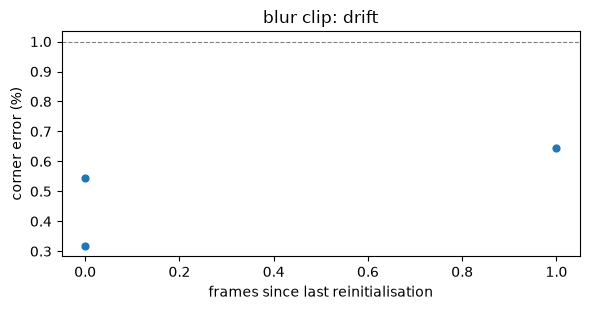

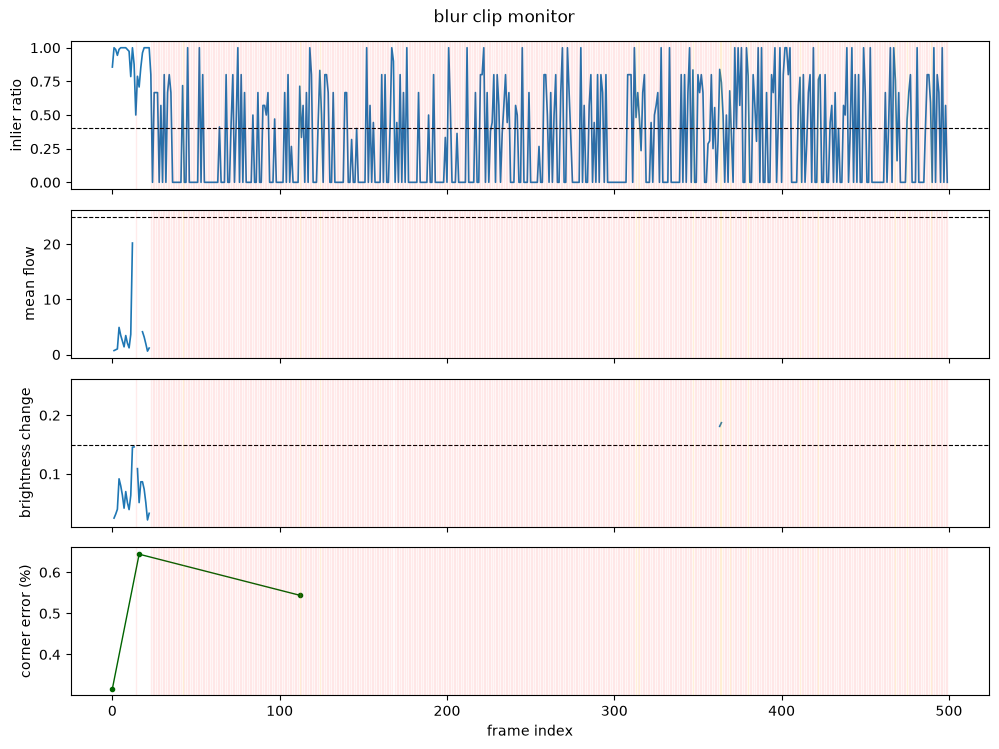

exit    : 22 scored audit frames, no scored point >=16 frames after reinit


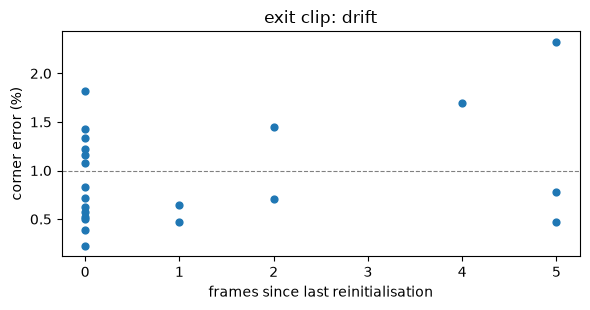

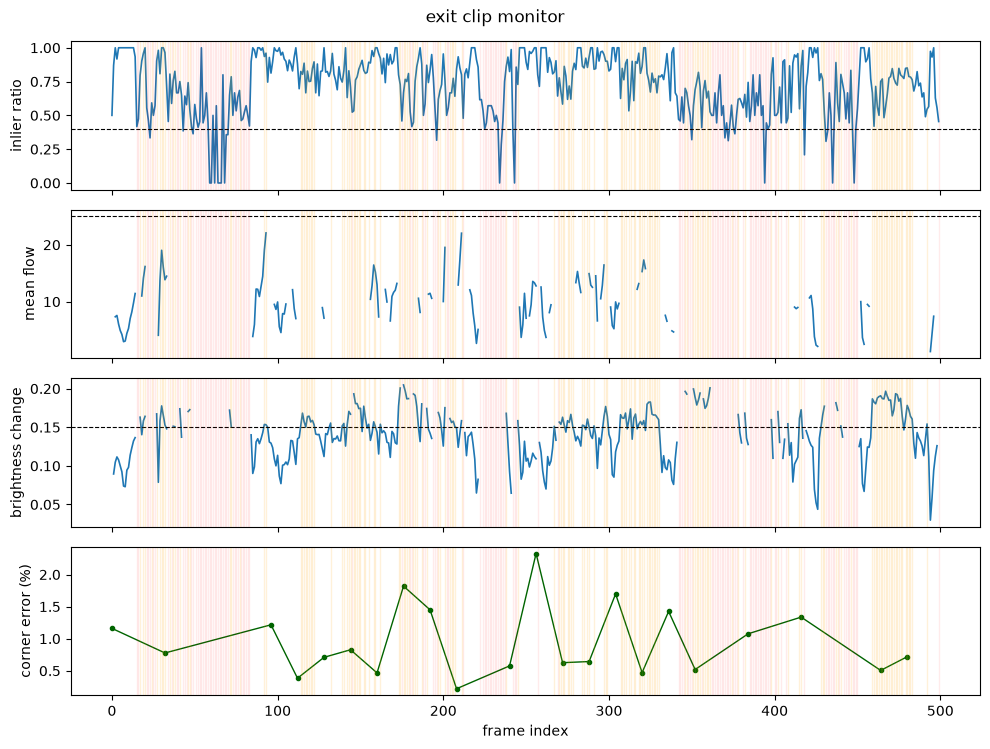

combined: 11 scored audit frames, no scored point >=16 frames after reinit


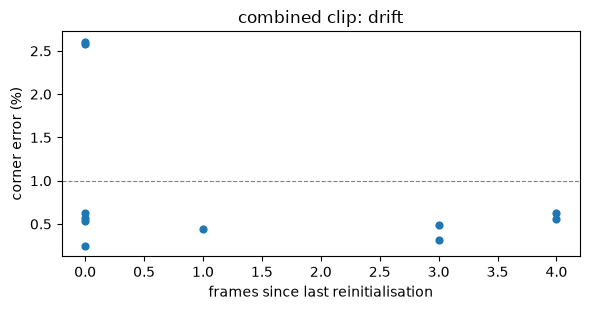

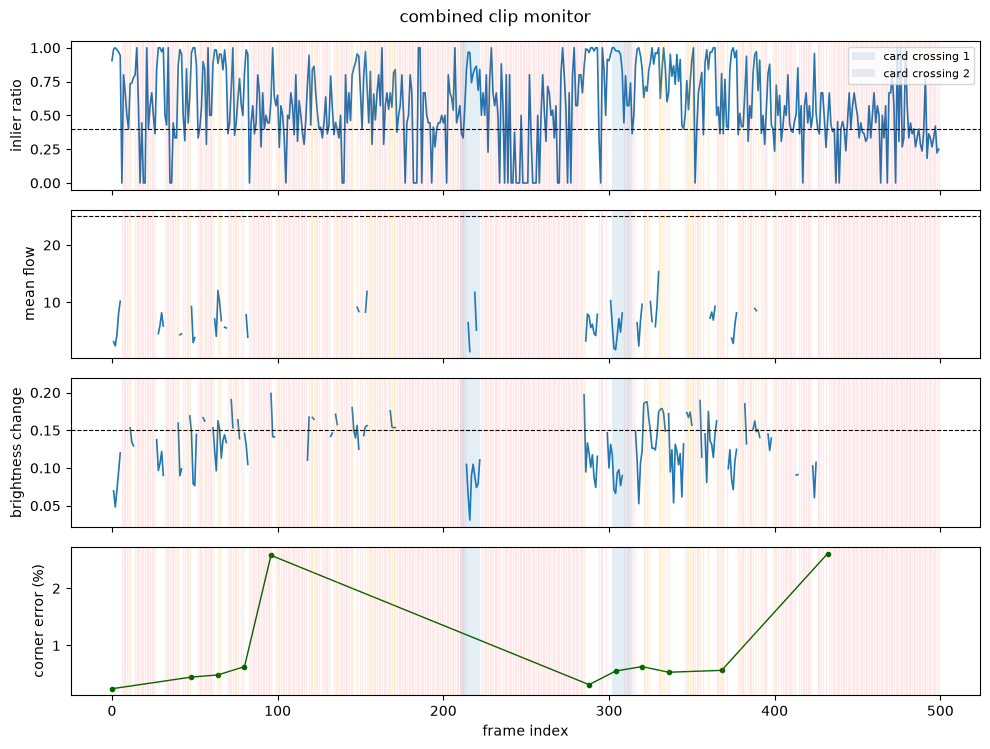

In [11]:
tables = ROOT / "outputs" / "stress_tables.md"
print(tables.read_text() if tables.exists() else "run the two commands above first: outputs/stress_tables.md not found")
# YOUR CODE HERE (optional) — load outputs/videos/<id>_<variant>_stats.json with overlaylab.pipelines.load_stats and plot the
# drift curve (metrics.drift) and the monitor timeline (viz.plot_monitor_timeline) of the blur, exit and combined clips

from overlaylab.pipelines import load_stats
diagnostic_runs = {
    "blur": data.stress_clips(2)["blur"],
    "exit": data.stress_clips(2)["exit"],
    "combined": data.stress_clips(3)["combined"],
}
loaded_any = False
for factor_name, clip_id in diagnostic_runs.items():
    stats_file = ROOT / "outputs" / "videos" / f"{clip_id}_flow_assisted_stats.json"
    if not stats_file.exists():
        print(f"missing {stats_file.name}; run the section 10 terminal commands first")
        continue
    loaded_any = True
    run = load_stats(stats_file)
    source_width = run.get("source_width") or sp.video_info(data.clip_paths(clip_id)[0])["width"]
    processing_width = run.get("frame_size", [source_width])[0]
    gt_run = data.load_diagnostic_corners(clip_id, scale=processing_width / source_width)
    flags_run = [tuple(flag) for flag in run["flags"]]
    hidden = {i for i, (flag, _) in enumerate(flags_run) if flag == "HIDE"}
    errors_run = {}
    for f, gt_corners_run in gt_run.items():
        if f < len(run["corners"]) and run["status"][f] == "ok" and f not in hidden:
            errors_run[f] = metrics.corner_error(run["corners"][f], gt_corners_run)
        else:
            errors_run[f] = float("inf")
    drift_run = metrics.drift(errors_run, run.get("reinit_frames", []))
    finite_drift = [(age, error) for age, error in drift_run if np.isfinite(error)]
    plt.figure(figsize=(6, 3.2))
    if finite_drift:
        age_run, error_run = np.asarray(finite_drift).T
        plt.scatter(age_run, error_run * 100, s=24)
        late_run = error_run[age_run >= 16]
        print(f"{factor_name:8s}: {len(finite_drift)} scored audit frames, longest scored age {int(age_run.max())}, "
              f"median drift >=16 frames {np.median(late_run)*100:.2f}%" if len(late_run) else
              f"{factor_name:8s}: {len(finite_drift)} scored audit frames, no scored point >=16 frames after reinit")
    plt.axhline(config.localisation.success_threshold * 100, color="gray", ls="--", lw=.8)
    plt.xlabel("frames since last reinitialisation"); plt.ylabel("corner error (%)")
    plt.title(f"{factor_name} clip: drift"); plt.tight_layout(); plt.show()

    monitor_saved = run.get("config", {}).get("track", {}).get("monitor", {})
    thresholds_run = {
        "inlier_ratio": monitor_saved.get("min_inlier_ratio", config.track.monitor.min_inlier_ratio),
        "mean_flow": monitor_saved.get("max_mean_flow", config.track.monitor.max_mean_flow),
        "brightness_change": monitor_saved.get("max_brightness_change", config.track.monitor.max_brightness_change),
    }
    events_run = ({"card crossing 1": (210, 222), "card crossing 2": (302, 314)}
                  if factor_name == "combined" else None)
    finite_errors_run = {f: error for f, error in errors_run.items() if np.isfinite(error)}
    viz.plot_monitor_timeline(run["stats"], flags_run, events_run, errors=finite_errors_run,
                              thresholds=thresholds_run, title=f"{factor_name} clip monitor")
    plt.show()
if not loaded_any:
    print("No saved diagnostic runs yet; this cell will populate after run_pipeline --all.")

## Reflection prompts
1. When does independent registration flicker, and when does the flow-assisted variant drift?
2. Which monitor statistic separates a physical occlusion from tracking drift, given that both lower the inlier ratio?
3. How would you reinitialise after the board re-enters the frame without using the ground truth?